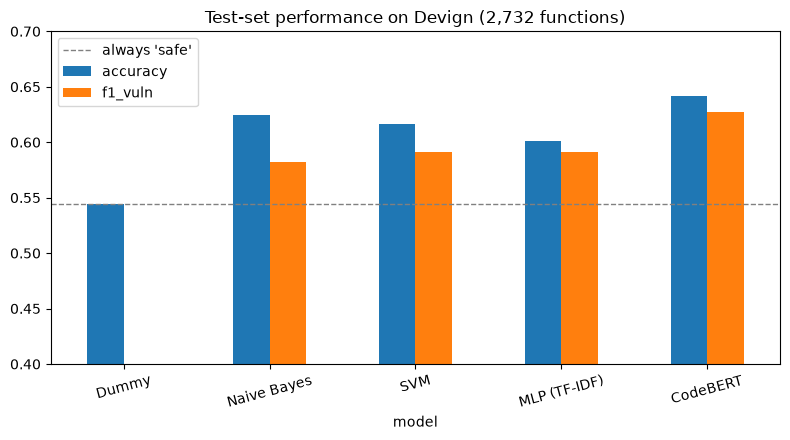

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.makedirs("../results", exist_ok=True)

rows = [
    ("Dummy",        0.544, np.nan, np.nan, np.nan),
    ("Naive Bayes",  0.625, 0.592, 0.573, 0.582),
    ("SVM",          0.616, 0.575, 0.608, 0.591),
    ("MLP (TF-IDF)", 0.601, 0.555, 0.632, 0.591),
    ("CodeBERT",     0.642, 0.597, 0.661, 0.627),
]
df = pd.DataFrame(rows, columns=["model", "accuracy", "precision_vuln", "recall_vuln", "f1_vuln"])
df.to_csv("../results/test_results.csv", index=False)

ax = df.set_index("model")[["accuracy", "f1_vuln"]].plot.bar(rot=15, figsize=(8, 4.5), ylim=(0.4, 0.7))
ax.axhline(0.544, color="gray", linestyle="--", linewidth=1, label="always 'safe'")
ax.set_title("Test-set performance on Devign (2,732 functions)")
ax.legend()
plt.tight_layout()
plt.savefig("../results/model_comparison.png", dpi=150)
plt.show()

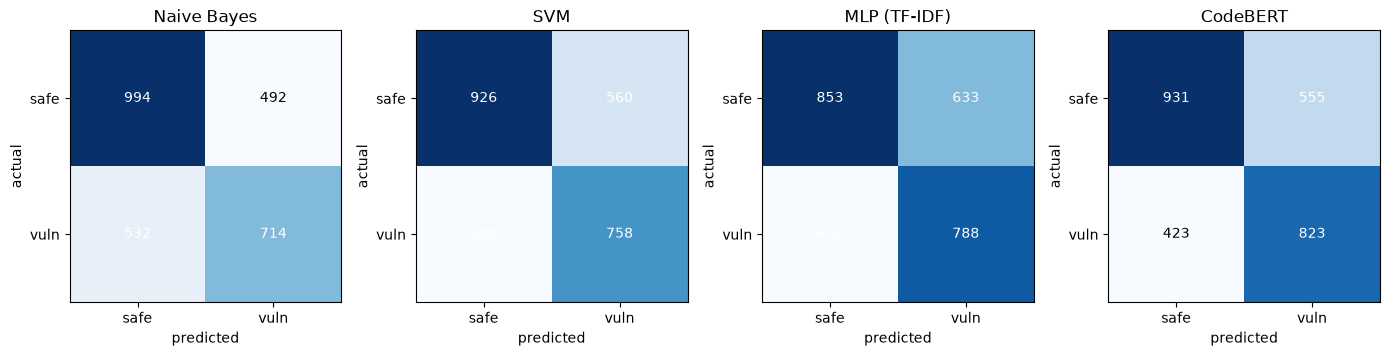

In [4]:
cms = {
    "Naive Bayes":  [[994, 492], [532, 714]],
    "SVM":          [[926, 560], [488, 758]],
    "MLP (TF-IDF)": [[853, 633], [458, 788]],
    "CodeBERT":     [[931, 555], [423, 823]],
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (name, cm) in zip(axes, cms.items()):
    cm = np.array(cm)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["safe", "vuln"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["safe", "vuln"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("../results/confusion_matrices.png", dpi=150)
plt.show()

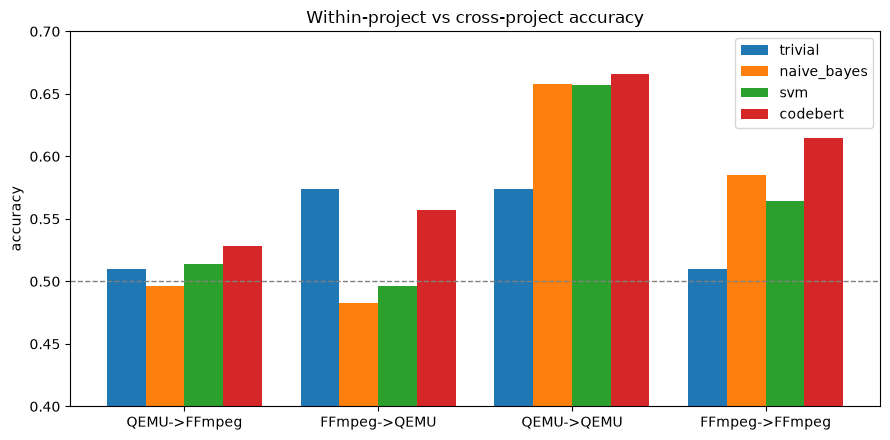

In [5]:
scen = ["QEMU->FFmpeg", "FFmpeg->QEMU", "QEMU->QEMU", "FFmpeg->FFmpeg"]
cp = pd.DataFrame({
    "scenario": scen,
    "trivial":   [0.510, 0.574, 0.574, 0.510],
    "naive_bayes": [0.496, 0.483, 0.658, 0.585],
    "svm":       [0.514, 0.496, 0.657, 0.564],
    "codebert":  [0.528, 0.557, 0.666, 0.615],
})
cp.to_csv("../results/cross_project_accuracy.csv", index=False)

x = np.arange(len(scen)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, col in enumerate(["trivial", "naive_bayes", "svm", "codebert"]):
    ax.bar(x + (k - 1.5) * w, cp[col], w, label=col)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(scen)
ax.set_ylim(0.4, 0.7)
ax.set_ylabel("accuracy")
ax.set_title("Within-project vs cross-project accuracy")
ax.legend()
plt.tight_layout()
plt.savefig("../results/cross_project.png", dpi=150)
plt.show()